# MLP и автоэнкодеры для табличных данных

В этом ноутбуке мы разберём задачу обнаружения мошеннических банковских транзакций и на её примере изучим:

- Устройство многослойного перцептрона (MLP).
- Подготовку табличных данных для нейросети.
- Проблему сильного дисбаланса классов.
- Почему `accuracy` может вводить в заблуждение.
- Основную метрику `Average Precision (AP)`; дополнительно — `Precision`, `Recall`, `F1`, `ROC-AUC`.
- `Dropout`, `Batch Normalization` и L2-регуляризацию.
- Автоэнкодер как модель для anomaly detection.
- Reconstruction error как anomaly score.
- Выбор порога для бинарного детектора (для AP порог не нужен).

> **Идея задачи:** мошеннические транзакции встречаются очень редко.  
> Мы рассмотрим два подхода:
>
> 1. **Supervised:** MLP учится напрямую различать `normal` и `fraud`.
> 2. **Anomaly detection:** автоэнкодер обучается только на нормальных транзакциях, а необычные объекты ищутся по большой ошибке восстановления.

**Запуск:** откройте notebook в Google Colab или Kaggle Notebooks и выполните все
ячейки по порядку (Run all). Нужен доступ в интернет для загрузки Credit Card;
в Kaggle включите Internet в настройках сессии. GPU можно включить для ускорения,
но CPU тоже подходит. Установка дополнительных пакетов и загрузка файлов вручную не нужны.

Если это ваша первая практика с DL, сначала выполните `00_pytorch_basics_v2_colab.ipynb`:
там разобраны тензоры, градиенты и шаг обучения, которые здесь используются без подробного повторения.

## Импорты и воспроизводимость

Мы будем использовать уже знакомые вам библиотеки:

- `pandas`, `numpy` — работа с таблицами;
- `scikit-learn` — разбиение данных, масштабирование и метрики;
- `PyTorch` — построение и обучение нейросетей;
- `matplotlib` — визуализация.

Фиксируем random seed для воспроизводимости в одной среде. На CPU и GPU, а также в разных версиях библиотек результаты могут немного отличаться.

In [88]:
import os
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import os, copy, json, random, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import average_precision_score, precision_recall_curve

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
SEED = 191

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Загрузка Credit Card Fraud Detection

Датасет содержит банковские транзакции. Целевая переменная:

- `Class = 0` — обычная транзакция;
- `Class = 1` — мошенническая транзакция.

Признаки `V1 ... V28` уже были преобразованы методом PCA (principal component analysis, он же метод главных компонент).  
Кроме них нам так же доступны `Time` и `Amount`.

Ниже используется публичная копия из [TensorFlow tutorial](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data).
Читаем её напрямую через `pandas`, без `kagglehub`. Перед разбиением удалим точные
дубли строк, чтобы копии одной записи не попали одновременно в train и test.

In [89]:
data_dir_env = os.environ.get("DL_HW1_DATA_DIR")
if data_dir_env:
    DATA_DIR = Path(data_dir_env)
else:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/DL_HW1_contest_data")

for name in ["train.csv", "test.csv", "sample_submission.csv"]:
    assert (DATA_DIR / name).is_file(), f"Не найден {DATA_DIR / name}"

df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
FEATURES = [f"sensor_{i}" for i in range(6)]

df = df.drop_duplicates(subset=FEATURES).reset_index(drop=True)


assert set(df.columns) == set(["id", "anomaly"] + FEATURES)
assert set(test_df.columns) == set(["id"] + FEATURES)
assert list(sample.columns) == ["id", "anomaly_score"]
assert df["id"].is_unique and test_df["id"].is_unique and sample["id"].is_unique
assert not df["id"].isin(test_df["id"]).any()
assert set(sample["id"]) == set(test_df["id"])
assert df["anomaly"].isin([0, 1]).all()
assert np.isfinite(df[FEATURES].to_numpy()).all()
assert np.isfinite(test_df[FEATURES].to_numpy()).all()
X = df[FEATURES].to_numpy(dtype=np.float32)
y = df["anomaly"].to_numpy(dtype=np.int64)
assert len(np.unique(y)) == 2
print("Train:", df.shape, "Test:", test_df.shape)
print("Anomaly counts:", df["anomaly"].value_counts().to_dict())
print("Дубли признаков:", df.duplicated(FEATURES).sum())



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: (5534, 8) Test: (3355, 7)
Anomaly counts: {0: 5356, 1: 178}
Дубли признаков: 0


In [90]:
FEATURES = [f"sensor_{i}" for i in range(6)]

X = df[FEATURES]
y = df["anomaly"].astype(np.int64)

X_contest_test = test_df[FEATURES]
test_ids = test_df["id"]

## Первичный анализ

Давайте внимательнее посмотрим на наш датасет, а именно:

- сколько объектов каждого класса;
- насколько сильный дисбаланс;

In [91]:
class_counts = df["anomaly"].value_counts().sort_index()
class_share = df["anomaly"].value_counts(normalize=True).sort_index()

summary = pd.DataFrame({
    "count": class_counts,
    "share": class_share
})
summary.index = ["normal (0)", "fraud (1)"]

display(summary)

,count,share
normal (0),5356,0.967835
fraud (1),178,0.032165


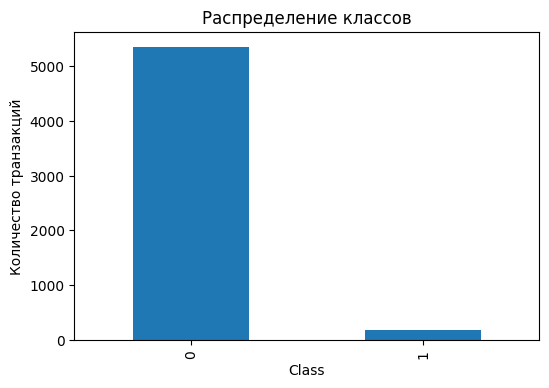

Доля fraud: 3.2165%
Доля normal: 96.7835%


In [92]:
fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot(kind="bar", ax=ax)
ax.set_title("Распределение классов")
ax.set_xlabel("Class")
ax.set_ylabel("Количество транзакций")
plt.show()

fraud_rate = df["anomaly"].mean()
print(f"Доля fraud: {fraud_rate:.4%}")
print(f"Доля normal: {1 - fraud_rate:.4%}")

Нетрудно заметить, что разница в соотношении классов просто колоссальная, и её обязательно нужно учитывать при решени задачи.

### Почему Accuracy здесь опасна?

Представим «модель», которая **всегда предсказывает `normal`**.

Если fraud составляет лишь малую долю выборки, такая модель получит почти идеальную accuracy — но не обнаружит ни одного случая мошенничества.

Это важный общий принцип:

> При сильном дисбалансе классов accuracy почти никогда не должна быть единственной метрикой.

In [93]:
'''y_all = df["anomaly"].values
always_normal = np.zeros_like(y_all)

print("Accuracy:", accuracy_score(y_all, always_normal))

# zero_division=0 для защиты от деления на 0, т. к. always_normal вообще не делает
# предсказаний класса 1 (TP = 0 и FP = 0), и знаменатель Precision становится равным нулю

print("Precision:", precision_score(y_all, always_normal, zero_division=0))
print("Recall:", recall_score(y_all, always_normal, zero_division=0))
print("F1:", f1_score(y_all, always_normal, zero_division=0))'''

'y_all = df["anomaly"].values\nalways_normal = np.zeros_like(y_all)\n\nprint("Accuracy:", accuracy_score(y_all, always_normal))\n\n# zero_division=0 для защиты от деления на 0, т. к. always_normal вообще не делает\n# предсказаний класса 1 (TP = 0 и FP = 0), и знаменатель Precision становится равным нулю\n\nprint("Precision:", precision_score(y_all, always_normal, zero_division=0))\nprint("Recall:", recall_score(y_all, always_normal, zero_division=0))\nprint("F1:", f1_score(y_all, always_normal, zero_division=0))'

## Метрики для fraud detection

Пусть положительный класс — `fraud`.

### Precision

$Precision = \frac{TP}{TP + FP}$
Отвечает на вопрос:

> Среди транзакций, которые модель назвала мошенническими, какая доля действительно является fraud?

Высокий Precision означает мало ложных тревог.

### Recall

$Recall = \frac{TP}{TP + FN}$

Отвечает на вопрос:

> Какую долю всех реальных мошеннических транзакций мы обнаружили?

Высокий Recall означает, что модель пропускает мало fraud.

### F1-score

$F_1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$

F1 балансирует Precision и Recall, но зависит от выбранного порога, по которому мы определяем, является ли класс положительным.

### ROC-AUC

ROC-кривая показывает зависимость TPR / Recall от FPR при изменении порога; ROC-AUC — площадь под ней. Это качество ранжирования, а не количество ложных тревог. При редком fraud небольшая FPR может соответствовать многим ложным тревогам, поэтому основной метрикой здесь будет AP.


### Average Precision (AP) — основная метрика

Для сильно несбалансированных задач особенно полезна Precision–Recall curve. Это зависимость Precision (из того, что модель назвала фродом, сколько реально оказалось фродом) от Recall (полноты: сколько вообще всего реального фрода в датасете нашла модель) так же при изменении порога.

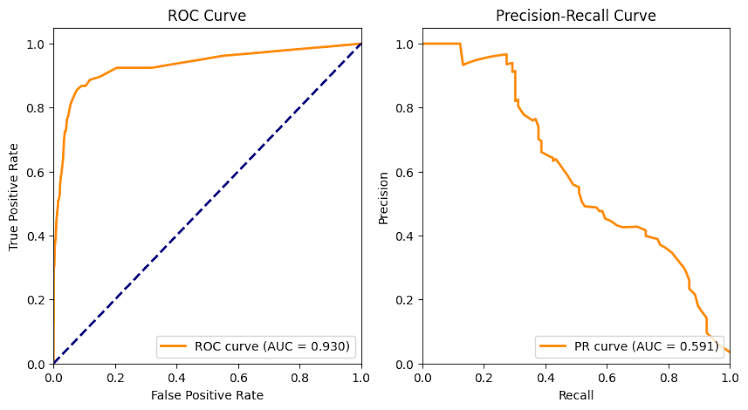

$$ True\ Positive\ Rate = \frac{TP}{TP + FN},\ False\ Positive\ Rate = \frac{FP}{FP + TN}$$

В этом ноутбуке для численной оценки площади будем использовать:

```python
average_precision_score(y_true, score)
```

Это **Average Precision (AP)** — ступенчатая сумма precision по приростам recall, без линейной интерполяции. Она не равна в общем случае трапецеидальной PR-AUC:
$$AP = \sum_n (R_n - R_{n-1})P_n,$$ где $P_n$ и $R_n$ — точность и полнота на $n$-м шаге изменения порога классификации.

Для AP передаём **непрерывные scores**, а не классы: чем выше score, тем подозрительнее
объект. Подбор порога не нужен. Одинаковые scores учитываются одной группой;
грубое округление может изменить AP. Постоянный score даёт AP, равную доле fraud.
В контесте baseline — **Public AP ≥ 0.2**; это порог метрики, а не score объекта.

## Train / Validation / Test split

Разбиваем данные **стратифицированно**, чтобы доля fraud оставалась примерно одинаковой. Без fraud в train модель не сможет учиться распознавать этот класс; без fraud в validation/test нельзя содержательно оценить его обнаружение.

Будем использовать:

- `train` — обучение;
- `validation` — выбор модели и эпохи по AP, threshold;
- `test` — финальная оценка.

Не забываем, что тест нельзя использовать для выбора гиперпараметров.

In [94]:
FEATURES = [f"sensor_{i}" for i in range(6)]
input_dim = len(FEATURES)
X = df[FEATURES]
y = df["anomaly"].astype(np.int64)

X_contest_test = test_df[FEATURES]
test_ids = test_df["id"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

print(
    f"train: n={len(y_train)}, "
    f"anomalies={y_train.sum()}, "
    f"share={y_train.mean():.4%}"
)

print(
    f"val:   n={len(y_val)}, "
    f"anomalies={y_val.sum()}, "
    f"share={y_val.mean():.4%}"
)

train: n=4427, anomalies=142, share=3.2076%
val:   n=1107, anomalies=36, share=3.2520%


## Масштабирование признаков

Нейросети (как и обычные ML-алгоритмы) обычно обучаются стабильнее, когда входные признаки имеют сопоставимый масштаб.

Особенно важно масштабировать:

- `Time`;
- `Amount`.

Это секунды от начала сбора данных (от 0 до сотен тысяч), а Amount — это сумма транзакции (могут быть как нулями, так и тысячами). Без нормализации эти два признака будут иметь гигантские абсолютные значения по сравнению с остальными.

`V1 ... V28` уже преобразованы PCA (они уже центрированы вокруг нуля и имеют компактный разброс), но для единообразия применим `StandardScaler` ко всем признакам.

**Критически важно:** `scaler.fit(...)` делается только на train.

In [95]:
'''
print("X:", X.columns.tolist())
print("X_train:", X_train.columns.tolist())
print("X_val:", X_val.columns.tolist())
print("X_contest_test:", X_contest_test.columns.tolist())
'''

'\nprint("X:", X.columns.tolist())\nprint("X_train:", X_train.columns.tolist())\nprint("X_val:", X_val.columns.tolist())\nprint("X_contest_test:", X_contest_test.columns.tolist())\n'

In [96]:
scaler = StandardScaler()

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)

X_test_scaled = scaler.transform(X_contest_test).astype(np.float32)

y_train_np = y_train.to_numpy().astype(np.float32)
y_val_np = y_val.to_numpy().astype(np.float32)

print(X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)

(4427, 6) (1107, 6) (3355, 6)


## DataLoader

`DataLoader` разбивает данные на мини-батчи для обучения.

Для обычного supervised MLP батч содержит:

```text
(features, label)
```

### тут Батч

In [97]:
BATCH_SIZE = 128

train_ds = TensorDataset(
    torch.tensor(X_train_scaled),
    torch.tensor(y_train_np),
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled),
    torch.tensor(y_val_np),
)
contest_test_ds = TensorDataset(
    torch.tensor(X_test_scaled)
)

# shuffle=True тут важен, чтобы при обучении нейросеть не запоминала порядок примеров и каждый раз видела батчи в новой случайной комбинации
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)

# А вот оценка модели на валидации и тесте должна быть детерминированной. Если включить shuffle=True,
# порядок батчей каждый раз будет случайным. Из-за этого некоторые метрики могут плавать от запуска к запуску,
# и вам будет тяжело сравнивать разные эксперименты между собой.
# В нашем случае перестановка пар (label, score) сама по себе AP/F1 не меняет, но оставим shuffle=False как правило хорошего тона
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
contest_test_loader = DataLoader(
    contest_test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

# Часть I. Supervised MLP

Перейдем к самой главной части этого урока. Итак, как вы уже знаете из лекций, MLP — это последовательность полносвязных слоёв.

Для одного слоя:

$z = Wx + b$, где W - матрица весов, b - смещение, он же bias.

После этого применяется нелинейная функция активации для моделирования нелинейных зависимостей в данных:

Например, `ReLU`: $ReLU(z)=\max(0,z)$, или `Sigmoid`: $h = \sigma(z)$.


Если последовательно использовать только линейные преобразования без функции активации, вся сеть математически сведётся к одному линейному преобразованию. Поэтому нелинейности критически важны.

В бинарной классификации (которой, по сути и является поиск аномалий) удобно выдавать один **logit** (сырое, ненормированное вещественное число, которые выдает последний линейный слой нейросети) и использовать `BCEWithLogitsLoss` (Binary Cross-Entropy Loss).

P. S. За счет грамотных математических преобразований `BCEWithLogitsLoss` является более вычислительно устойчивым, чем последовательное применение `Sigmoid` и `BCELoss`, поэтому предпочтение отдаем именно ему.

Сформируем наш персептрон:

In [98]:
class MLP(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dims=(64, 32),
        dropout=0.0,
        use_batchnorm=False,
        activation="relu",
    ):
        super().__init__()

        activations = {
            "relu": lambda: nn.ReLU(),
            "leaky_relu": lambda: nn.LeakyReLU(negative_slope=0.03),
            "gelu": lambda: nn.GELU(),
            "silu": lambda: nn.SiLU(),
        }

        if activation not in activations:
            raise ValueError(
                f"Неизвестная activation={activation}. "
                f"Доступны: {list(activations.keys())}"
            )

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(
                nn.Linear(prev_dim, hidden_dim)
            )

            if use_batchnorm:
                layers.append(
                    nn.BatchNorm1d(hidden_dim)
                )

            layers.append(
                activations[activation]()
            )

            if dropout > 0:
                layers.append(
                    nn.Dropout(dropout)
                )

            prev_dim = hidden_dim

        # Последний слой без activation,
        # потому что используем BCEWithLogitsLoss
        layers.append(
            nn.Linear(prev_dim, 1)
        )

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)

## Dropout, BatchNorm и L2-регуляризация

### Dropout

Во время обучения зануляет каждую активацию с вероятностью $p$ и масштабирует оставшиеся; сами веса не зануляются. В режиме `eval()` Dropout отключён. Идея в том, что сеть не должна слишком сильно зависеть от отдельных нейронов. При грамотном применении позволяет усилить обобщающую способность сети.

### Batch Normalization

Нормализует промежуточные представления внутри мини-батча (то есть считает среднее значение и дисперсия признаков по батчу) и затем обучает собственные параметры масштаба и сдвига (иногда нейросети нужно более широкое или смещенное распределение, например, чтобы не «убивать» нелинейность функций активации вроде ReLU для отрицательных значений). Часто помогает сделать обучение более стабильным, так как борется со изменением распределения данных в процессе обучения. В `train()` использует статистики текущего батча и обновляет накопленные оценки; в `eval()` использует накопленные оценки.

### L2-регуляризация

Как вы знаете из лекций, штрафует большие веса пропорционально квадрату их нормы. В примерах ниже `AdamW(weight_decay=...)` отдельно уменьшает веса на каждом шаге. При грамотной настройке, как и Dropout, препятствует переобучению и повышает обобщающую способность.

## Loss для несбалансированной классификации

Fraud в нашей выборке очень редок (его доля меньше процента!), поэтому можно сильнее учитывать положительные примеры в функции потерь.

Для `BCEWithLogitsLoss` есть параметр `pos_weight`.

Используем:

$pos\_weight = \frac{N_{negative}}{N_{positive}}$

Это не единственный способ борьбы с дисбалансом, но хороший baseline. Позже можно попробовать другие веса.

### тут POS и слои

In [99]:
POS = 1.5

DIMS = (128,64,32) # Need to try

DIMS = (128,128,64,64,32) # 0.855

DIMS = (128,128,64,64) # AP = 0.87

DIMS = (128,128,64)

#DIMS = (256,128,64) 0.86

#DIMS = (128,64,64,32) #0.857

In [100]:
n_pos = y_train.sum()
n_neg = len(y_train) - n_pos
'''

'''
pos_weight_value = POS

pos_weight_value = n_neg / n_pos
pos_weight_value /= 3

pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

print("pos_weight:", float(pos_weight_value))

pos_weight: 10.05868544600939


## Функции обучения

Будем отслеживать loss, но сохранять лучшую модель по **validation AP**.
Градиенты считаются для BCE: AP используется только для выбора эпохи.

Для учебного ноутбука используем небольшой `patience` для early stopping.

In [101]:
def train_classifier(
    model,
    train_loader,
    val_loader,
    epochs=70,
    lr=1e-3,
    weight_decay=0.0,
    patience=10,
    pos_weight_value = POS
):
    pos_weight = torch.tensor(
        [pos_weight_value],
        dtype=torch.float32,
        device=device,
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weight
    )
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    history = {"train_loss": [], "val_loss": [], "val_ap": []}
    best_val_ap = -float("inf")
    best_state = copy.deepcopy(model.state_dict())
    bad_epochs = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item() * len(xb))

        model.eval()
        val_losses = []
        val_scores, val_targets = [], []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(xb)
                loss = criterion(logits, yb)
                val_losses.append(loss.item() * len(xb))
                val_scores.append(torch.sigmoid(logits).cpu().numpy())
                val_targets.append(yb.cpu().numpy())

        train_loss = np.sum(train_losses) / len(train_loader.dataset)
        val_loss = np.sum(val_losses) / len(val_loader.dataset)
        val_ap = average_precision_score(np.concatenate(val_targets), np.concatenate(val_scores))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_ap"].append(val_ap)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_loss:.5f} | "
            f"val_loss={val_loss:.5f} | val_AP={val_ap:.5f}"
        )

        if val_ap > best_val_ap:
            best_val_ap = val_ap
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            print("Early stopping")
            break

    model.load_state_dict(best_state)
    return history


def predict_classifier(model, loader):
    model.eval()

    all_probs = []
    all_targets = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)

            logits = model(xb)
            probs = torch.sigmoid(logits)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(yb.numpy())

    return np.concatenate(all_targets), np.concatenate(all_probs)

## Обучаем baseline MLP

In [102]:
baseline_mlp = MLP(
    input_dim=input_dim,
    hidden_dims=DIMS,
    dropout=0.0,
    use_batchnorm=False,
    activation="relu",
).to(device)

history_baseline = train_classifier(
    baseline_mlp,
    train_loader,
    val_loader,
    epochs=120,
    patience = 16,
    lr=1e-3,
    weight_decay=0.0,
)

Epoch 01 | train_loss=0.39684 | val_loss=0.21669 | val_AP=0.05688
Epoch 02 | train_loss=0.16535 | val_loss=0.12289 | val_AP=0.59848
Epoch 03 | train_loss=0.12183 | val_loss=0.11097 | val_AP=0.57860
Epoch 04 | train_loss=0.11269 | val_loss=0.10534 | val_AP=0.59046
Epoch 05 | train_loss=0.10626 | val_loss=0.10302 | val_AP=0.59887
Epoch 06 | train_loss=0.10285 | val_loss=0.10107 | val_AP=0.61074
Epoch 07 | train_loss=0.09886 | val_loss=0.09662 | val_AP=0.62574
Epoch 08 | train_loss=0.09619 | val_loss=0.09495 | val_AP=0.66541
Epoch 09 | train_loss=0.09360 | val_loss=0.09244 | val_AP=0.67155
Epoch 10 | train_loss=0.09092 | val_loss=0.09482 | val_AP=0.64580
Epoch 11 | train_loss=0.08874 | val_loss=0.09171 | val_AP=0.67863
Epoch 12 | train_loss=0.08737 | val_loss=0.08870 | val_AP=0.69666
Epoch 13 | train_loss=0.08449 | val_loss=0.08987 | val_AP=0.70302
Epoch 14 | train_loss=0.08191 | val_loss=0.08920 | val_AP=0.70042
Epoch 15 | train_loss=0.08099 | val_loss=0.08891 | val_AP=0.72096
Epoch 16 |

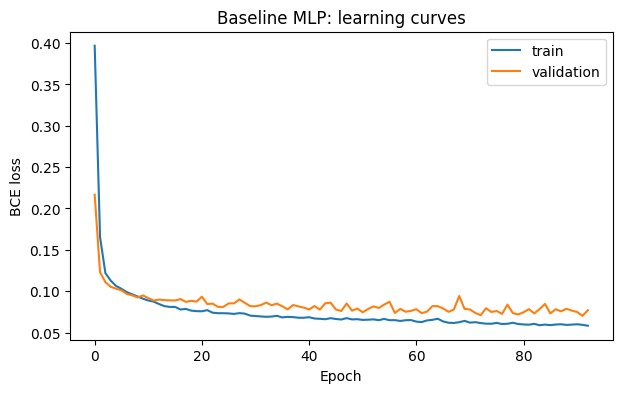

In [103]:
plt.figure(figsize=(7, 4))
plt.plot(history_baseline["train_loss"], label="train")
plt.plot(history_baseline["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("Baseline MLP: learning curves")
plt.legend()
plt.show()

## Оценка модели: score и threshold

После sigmoid MLP выдаёт score от 0 до 1. Score не обязан быть калиброванной вероятностью fraud.

Для основной метрики AP используем score напрямую. Для дополнительных `Precision`, `Recall`, `F1` нужен порог, превращающий score в класс.

Стандартный threshold `0.5` не обязательно оптимален.

Сначала оценим threshold-independent метрики:

- **Average Precision**;
- ROC-AUC (дополнительно).

In [104]:
y_val_true, val_probs = predict_classifier(baseline_mlp, val_loader)

print("ROC-AUC:", roc_auc_score(y_val_true, val_probs))
print("Average Precision:", average_precision_score(y_val_true, val_probs))

ROC-AUC: 0.9563751426496525
Average Precision: 0.7948076992880616


## Precision–Recall curve

На PR-кривой точки соответствуют разным threshold.

Это позволяет увидеть trade-off:

- более низкий threshold → больше Recall, но обычно ниже Precision;
- более высокий threshold → выше Precision, но часть fraud будет пропущена.

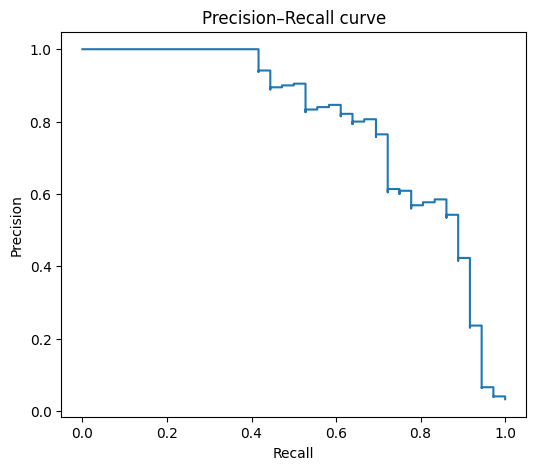

In [105]:
precision, recall, thresholds = precision_recall_curve(y_val_true, val_probs)

plt.figure(figsize=(6, 5))
plt.step(recall, precision, where="post")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall curve")
plt.show()

## Эксперимент: Dropout, BatchNorm, L2

Теперь сравним несколько вариантов.

Чтобы сравнение было честнее, оставляем одинаковыми:

- train/validation split;
- hidden dimensions;
- optimizer;
- learning rate;
- число эпох.

Меняем только регуляризацию.

Ранжируем варианты по **validation AP**. В таблице сохранены дополнительные F1-метрики.

In [ ]:
experiments = {
    "baseline": {
        "dropout": 0.0,
        "batchnorm": False,
        "weight_decay": 0.0,
    },
    "dropout": {
        "dropout": 0.01,
        "batchnorm": False,
        "weight_decay": 0.0,
    },
    "batchnorm": {
        "dropout": 0.0,
        "batchnorm": True,
        "weight_decay": 0.0,
    },
    "batchnorm_l2": {
        "dropout": 0.0,
        "batchnorm": True,
        "weight_decay": 1e-4,
    },
    "l2": {
        "dropout": 0.0,
        "batchnorm": False,
        "weight_decay": 1e-4,
    },
    "bn_dropout_l2": {
        "dropout": 0.01,
        "batchnorm": True,
        "weight_decay": 1e-4,
    },
}


ACTIVATIONS = [
    #"relu",
    #"leaky_relu",
    "gelu",
    "silu",
]


classifier_results = []
trained_classifiers = {}


for activation in ACTIVATIONS:

    for name, cfg in experiments.items():

        experiment_name = f"{name}_{activation}"

        print("\n" + "=" * 70)
        print("Experiment:", experiment_name)

        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

        model = MLP(
            input_dim=input_dim,
            hidden_dims=DIMS,
            dropout=cfg["dropout"],
            use_batchnorm=cfg["batchnorm"],
            activation=activation,
        ).to(device)

        history = train_classifier(
            model,
            train_loader,
            val_loader,
            epochs=110,
            lr=1e-3,
            weight_decay=cfg["weight_decay"],
            patience=16,
        )

        y_true_tmp, scores_tmp = predict_classifier(
            model,
            val_loader
        )

        ap = average_precision_score(
            y_true_tmp,
            scores_tmp
        )

        roc_auc = roc_auc_score(
            y_true_tmp,
            scores_tmp
        )

        classifier_results.append({
            "experiment": experiment_name,
            "model": name,
            "activation": activation,
            "dropout": cfg["dropout"],
            "batchnorm": cfg["batchnorm"],
            "weight_decay": cfg["weight_decay"],
            "AP": ap,
            "ROC_AUC": roc_auc,
        })

        trained_classifiers[experiment_name] = model

        print(f"Validation AP: {ap:.5f}")
        print(f"Validation ROC-AUC: {roc_auc:.5f}")


classifier_results_df = (
    pd.DataFrame(classifier_results)
    .sort_values("AP", ascending=False)
    .reset_index(drop=True)
)

classifier_results_df


Experiment: baseline_relu
Epoch 01 | train_loss=0.39684 | val_loss=0.21669 | val_AP=0.05688
Epoch 02 | train_loss=0.16535 | val_loss=0.12289 | val_AP=0.59848
Epoch 03 | train_loss=0.12183 | val_loss=0.11097 | val_AP=0.57860
Epoch 04 | train_loss=0.11269 | val_loss=0.10534 | val_AP=0.59046
Epoch 05 | train_loss=0.10626 | val_loss=0.10302 | val_AP=0.59887
Epoch 06 | train_loss=0.10285 | val_loss=0.10107 | val_AP=0.61074
Epoch 07 | train_loss=0.09886 | val_loss=0.09662 | val_AP=0.62574
Epoch 08 | train_loss=0.09619 | val_loss=0.09495 | val_AP=0.66541
Epoch 09 | train_loss=0.09360 | val_loss=0.09244 | val_AP=0.67155
Epoch 10 | train_loss=0.09092 | val_loss=0.09482 | val_AP=0.64580
Epoch 11 | train_loss=0.08874 | val_loss=0.09171 | val_AP=0.67863
Epoch 12 | train_loss=0.08737 | val_loss=0.08870 | val_AP=0.69666
Epoch 13 | train_loss=0.08449 | val_loss=0.08987 | val_AP=0.70302
Epoch 14 | train_loss=0.08191 | val_loss=0.08920 | val_AP=0.70042
Epoch 15 | train_loss=0.08099 | val_loss=0.08891 

### Глядя на результаты, можно немного порассуждать?

1. Улучшил ли Dropout **validation AP** относительно baseline? Совпадает ли вывод по AP и F1?

По метрике F1-score и precision Dropout показывает лучший результат среди всех моделей, превосходя baseline. Однако по AP (Average Precision) он довольно близок к бейзлайну ($\approx 0.82$), а по ROC_AUC (0.974) незначительно уступает ему (0.978). Таким образом, Dropout улучшил качество классификации на оптимальном пороге (F1), но глобально по ранжированию вероятностей (ROC_AUC/AP) эффект неоднозначен.

2. Улучшил ли BatchNorm validation AP в текущем запуске?

Да. Модель с BatchNorm (batchnorm) демонстрирует лучший результат по AP и ROC_AUC среди всех представленных вариантов, заметно превосходя baseline.

3. Почему нельзя сделать вывод «BatchNorm всегда улучшает нейросеть»?

Эффект зависит от архитектуры, размера батча и данных. При слишком маленьких
батчах оценки среднего и дисперсии могут быть шумными.

4. Почему более сильная регуляризация может ухудшить модель?

Избыточная регуляризация (слишком высокий коэффициент L2-штрафа или большая доля дропаута) приводит к недообучению (underfitting). Модель становится излишне «простой» или теряет способность улавливать сложные закономерности в данных, из-за чего падает её общая предсказательная сила (что мы видим, например, в строке baseline или при комбинациях, где жесткие ограничения снижают AP по сравнению с чистым BatchNorm).

В завершение этой части посмотрим качество на тесте.

In [ ]:
def predict_test(model, loader):
    model.eval()

    all_probs = []

    with torch.no_grad():
        for (xb,) in loader:
            xb = xb.to(device)

            logits = model(xb)
            probs = torch.sigmoid(logits)

            all_probs.append(
                probs.cpu().numpy()
            )

    return np.concatenate(all_probs)

In [ ]:
# Лучшая модель по validation AP
best_clf_name = classifier_results_df.iloc[0]["experiment"]

best_clf_model = trained_classifiers[
    best_clf_name
]
# Проверяем качество на validation
y_val_true, val_scores_clf = predict_classifier(
    best_clf_model,
    val_loader
)

val_ap = average_precision_score(
    y_val_true,
    val_scores_clf
)

print("Best classifier by validation AP:", best_clf_name)
print("Validation AP:", val_ap)

# Предсказываем конкурсный test
test_scores_clf = predict_test(
    best_clf_model,
    contest_test_loader
)

print("Test predictions shape:", test_scores_clf.shape)
print("Score range:", test_scores_clf.min(), test_scores_clf.max())

In [ ]:
submission = pd.DataFrame({
    "id": test_ids,
    "anomaly_score": test_scores_clf,
})

submission.head()

In [ ]:
submission.to_csv(
    "submission.csv",
    index=False
)

In [ ]:
pd.read_csv("submission.csv").head()